In [1]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix

df_model = pd.read_csv('../data/df_final_features.csv', parse_dates=['date'])

feature_cols = [
    'home_forma_goles_favor', 'home_forma_goles_contra', 'home_forma_xg', 'home_forma_puntos',
    'away_forma_goles_favor', 'away_forma_goles_contra', 'away_forma_xg', 'away_forma_puntos',
    'home_dias_desde_ultimo_partido', 'away_dias_desde_ultimo_partido',
    'home_forma_ppda', 'away_forma_ppda',
]

# Target numérico (XGBoost no acepta strings)
target_map = {'Victoria visitante': 0, 'Empate': 1, 'Victoria local': 2}
df_model['target'] = df_model['resultado'].map(target_map)

# Drop solo por cold-start en forma_* (el gap se queda con NaN a propósito, ver arriba)
forma_feature_cols = [c for c in feature_cols if 'dias' not in c]
df_model = df_model.dropna(subset=forma_feature_cols)

# Split temporal — nunca random en series de tiempo
train = df_model[df_model['date'] < '2022-08-01']
test  = df_model[df_model['date'] >= '2022-08-01']

X_train, y_train = train[feature_cols], train['target']
X_test, y_test = test[feature_cols], test['target']

print(f"Train: {len(X_train)} partidos ({train['date'].min().date()} → {train['date'].max().date()})")
print(f"Test:  {len(X_test)} partidos ({test['date'].min().date()} → {test['date'].max().date()})")

Train: 3019 partidos (2014-08-29 → 2022-05-22)
Test:  1140 partidos (2022-08-12 → 2025-05-25)


In [2]:
model = XGBClassifier(
    objective='multi:softprob',
    eval_metric='mlogloss',
    n_estimators=300,
    max_depth=4,           # bajo a propósito: ~4000 filas de train, cuidado con overfitting
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
model.fit(X_train, y_train)

probs = model.predict_proba(X_test)
preds = model.predict(X_test)

In [3]:
# Nunca evalúes solo con accuracy — necesitas un baseline "tonto" para comparar
majority_class = y_train.mode()[0]
naive_acc = accuracy_score(y_test, [majority_class] * len(y_test))

print("Accuracy modelo:        ", accuracy_score(y_test, preds))
print("Accuracy baseline naive:", naive_acc)   # siempre predice la clase mayoritaria (normalmente 'Victoria local')
print("Log-loss modelo:        ", log_loss(y_test, probs))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, preds))

Accuracy modelo:         0.4728070175438597
Accuracy baseline naive: 0.4543859649122807
Log-loss modelo:         1.0592907667160034

Matriz de confusión:
 [[119  51 159]
 [ 79  33 181]
 [ 77  54 387]]


/home/angel/sistema-multiagente-futbol/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


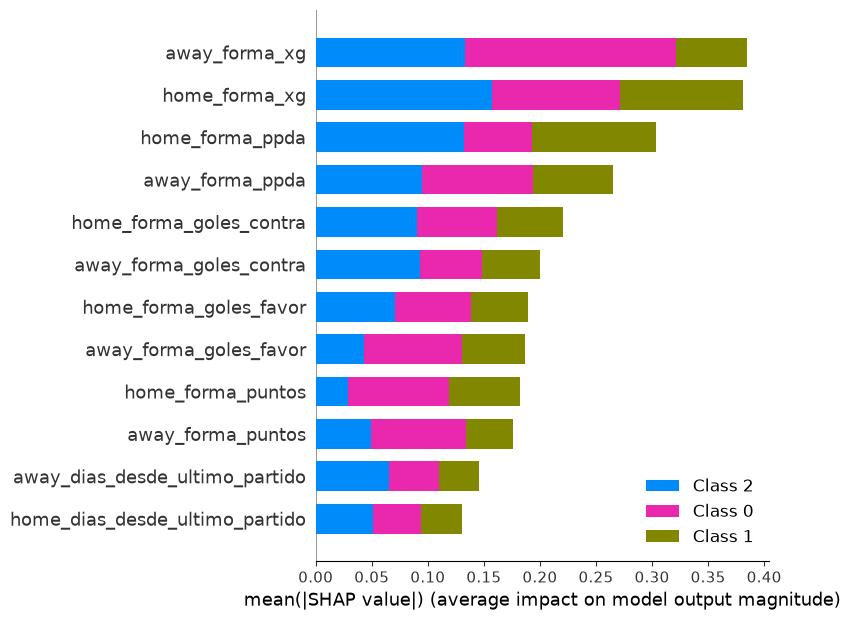

In [4]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Importancia global: qué feature mueve más las predicciones en promedio
shap.summary_plot(shap_values, X_test, plot_type='bar')

In [5]:
# Complementario: importancia nativa de XGBoost (basada en ganancia por split)
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

away_forma_xg                     0.099881
home_forma_xg                     0.095805
home_forma_puntos                 0.089178
away_forma_goles_favor            0.088970
away_forma_puntos                 0.086528
home_forma_goles_favor            0.082351
home_forma_goles_contra           0.079825
home_forma_ppda                   0.079115
away_forma_ppda                   0.077191
away_forma_goles_contra           0.077040
home_dias_desde_ultimo_partido    0.072112
away_dias_desde_ultimo_partido    0.072004
dtype: float32


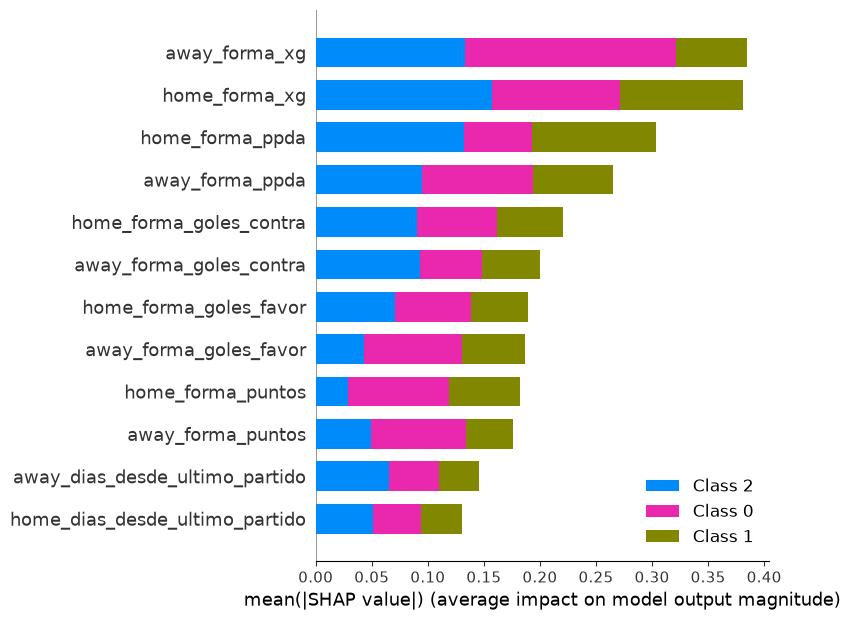

In [6]:
shap.summary_plot(shap_values, X_test, plot_type='bar')

In [7]:
X_train[['home_forma_xg', 'home_forma_ppda', 'away_forma_xg', 'away_forma_ppda']].corr()

,home_forma_xg,home_forma_ppda,away_forma_xg,away_forma_ppda
home_forma_xg,1.000000,-0.208902,0.013001,-0.026417
home_forma_ppda,-0.208902,1.000000,-0.044569,0.091108
away_forma_xg,0.013001,-0.044569,1.000000,-0.218109
away_forma_ppda,-0.026417,0.091108,-0.218109,1.000000


In [8]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from xgboost import XGBClassifier

tscv = TimeSeriesSplit(n_splits=5)

param_dist = {
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'n_estimators': [200, 300, 500],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
}

base_model = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=42)

search = RandomizedSearchCV(
    base_model,
    param_distributions=param_dist,
    n_iter=30,              # prueba 30 combinaciones al azar, no las cientos posibles del grid completo
    scoring='neg_log_loss', # sklearn siempre "maximiza", por eso el signo negativo (minimizar log-loss = maximizar -log-loss)
    cv=tscv,
    random_state=42,
    n_jobs=-1,              # usa todos los núcleos del CPU en paralelo
)
search.fit(X_train, y_train)   # ¡importante! solo con X_train — el test se queda intocado hasta el final

print("Mejores hiperparámetros:", search.best_params_)
print("Mejor log-loss (promedio en validación cruzada):", -search.best_score_)

KeyboardInterrupt: 

In [ ]:
best_model = search.best_estimator_
probs = best_model.predict_proba(X_test)
preds = best_model.predict(X_test)

print("Accuracy modelo tuneado:", accuracy_score(y_test, preds))
print("Log-loss modelo tuneado:", log_loss(y_test, probs))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, preds))

Accuracy modelo tuneado: 0.4982456140350877
Log-loss modelo tuneado: 1.0188862085342407

Matriz de confusión:
 [[116  15 198]
 [ 75  16 202]
 [ 68  14 436]]


In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

best_model.fit(X_train, y_train, sample_weight=sample_weights)

probs_bal = best_model.predict_proba(X_test)
preds_bal = best_model.predict(X_test)

print("Accuracy balanceado:", accuracy_score(y_test, preds_bal))
print("Log-loss balanceado:", log_loss(y_test, probs_bal))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, preds_bal))

Accuracy balanceado: 0.45614035087719296
Log-loss balanceado: 1.051269292831421

Matriz de confusión:
 [[158 102  69]
 [101  92 100]
 [103 145 270]]


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
}

for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)
    print(f"{nombre} — Accuracy: {accuracy_score(y_test, m.predict(X_test)):.4f}, Log-loss: {log_loss(y_test, p):.4f}")

Regresión Logística — Accuracy: 0.4561, Log-loss: 1.0623
Random Forest — Accuracy: 0.4482, Log-loss: 1.0531


In [ ]:
import joblib

joblib.dump(best_model, '../data/modelo_predictivo_laliga.pkl')

def ultima_forma(equipo: str, fecha: pd.Timestamp, team_matches: pd.DataFrame) -> dict | None:
    """Reconstruye la forma reciente de un equipo mirando hacia atrás desde 'fecha'."""
    historial = team_matches[(team_matches['team'] == equipo) & (team_matches['date'] < fecha)].sort_values('date')
    if historial.empty:
        return None
    ultimos5 = historial.tail(5)
    gap = (fecha - historial['date'].iloc[-1]).days
    return {
        'forma_goles_favor': ultimos5['goals_for'].mean(),
        'forma_goles_contra': ultimos5['goals_against'].mean(),
        'forma_xg': ultimos5['xg_for'].mean(),
        'forma_puntos': ultimos5['puntos'].mean(),
        'forma_ppda': ultimos5['ppda_for'].mean(),
        'dias_desde_ultimo_partido': gap,
    }

def predecir_partido(home_team: str, away_team: str, fecha: str, team_matches: pd.DataFrame, modelo, feature_cols: list) -> dict:
    fecha = pd.to_datetime(fecha)
    h, a = ultima_forma(home_team, fecha, team_matches), ultima_forma(away_team, fecha, team_matches)
    if h is None or a is None:
        return {'error': f"Sin historial suficiente para {home_team if h is None else away_team}"}

    fila = pd.DataFrame([{f'home_{k}': v for k, v in h.items()} | {f'away_{k}': v for k, v in a.items()}])[feature_cols]
    probs = modelo.predict_proba(fila)[0]
    return {'victoria_local': float(probs[2]), 'empate': float(probs[1]), 'victoria_visitante': float(probs[0])}

In [ ]:
team_matches = pd.read_csv('../data/team_matches.csv', parse_dates=['date'])

In [ ]:
print(sorted(team_matches['team'].unique()))

['Alaves', 'Almeria', 'Athletic Club', 'Atletico Madrid', 'Barcelona', 'Cadiz', 'Celta Vigo', 'Cordoba', 'Deportivo La Coruna', 'Eibar', 'Elche', 'Espanyol', 'Getafe', 'Girona', 'Granada', 'Las Palmas', 'Leganes', 'Levante', 'Malaga', 'Mallorca', 'Osasuna', 'Rayo Vallecano', 'Real Betis', 'Real Madrid', 'Real Sociedad', 'Real Valladolid', 'SD Huesca', 'Sevilla', 'Sporting Gijon', 'Valencia', 'Villarreal']


In [ ]:
partido_real = df_model.sort_values('date').iloc[-1]  # el partido más reciente de tu dataset
print(partido_real[['home_team', 'away_team', 'date', 'resultado']])

h_reconstruido = ultima_forma(partido_real['home_team'], partido_real['date'], team_matches)
h_precalculado = partido_real[['home_forma_goles_favor','home_forma_goles_contra','home_forma_xg',
                                'home_forma_puntos','home_forma_ppda','home_dias_desde_ultimo_partido']]

print("Reconstruido: ", h_reconstruido)
print("Precalculado: ", dict(h_precalculado))

home_team          Athletic Club
away_team              Barcelona
date         2025-05-25 19:00:00
resultado     Victoria visitante
Name: 4179, dtype: object
Reconstruido:  {'forma_goles_favor': np.float64(1.0), 'forma_goles_contra': np.float64(0.0), 'forma_xg': np.float64(1.342), 'forma_puntos': np.float64(2.6), 'forma_ppda': np.float64(10.559999999999999), 'dias_desde_ultimo_partido': 7}
Precalculado:  {'home_forma_goles_favor': np.float64(1.0), 'home_forma_goles_contra': np.float64(0.0), 'home_forma_xg': np.float64(1.342), 'home_forma_puntos': np.float64(2.6), 'home_forma_ppda': np.float64(10.56), 'home_dias_desde_ultimo_partido': np.float64(7.0)}


In [ ]:
resultado = predecir_partido(
    home_team='Real Madrid',      # usa un nombre real de la celda 2
    away_team='Barcelona',        # usa un nombre real de la celda 2
    fecha='2025-06-01',           # posterior a tu último partido registrado
    team_matches=team_matches,
    modelo=best_model,
    feature_cols=feature_cols,
)
print(resultado)

{'victoria_local': 0.36428210139274597, 'empate': 0.32184725999832153, 'victoria_visitante': 0.3138706684112549}
